In [17]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

In [18]:
image = cv2.imread('sar_3.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
image_inverted = cv2.bitwise_not(image_gray)
blurred = cv2.GaussianBlur(image_inverted, (5, 5), 0)

In [19]:
canny = cv2.Canny(blurred, 100, 200)

In [20]:
lines = cv2.HoughLinesP(canny, 1, np.pi/180, threshold=100, minLineLength=100, maxLineGap=20)

In [21]:
image_with_lines = image.copy()
if lines is not None:
    for line in lines:
        x1, y1, x2, y2 = line.ravel()
        cv2.line(image_with_lines, (x1, y1), (x2, y2), (0, 255, 255), 2)

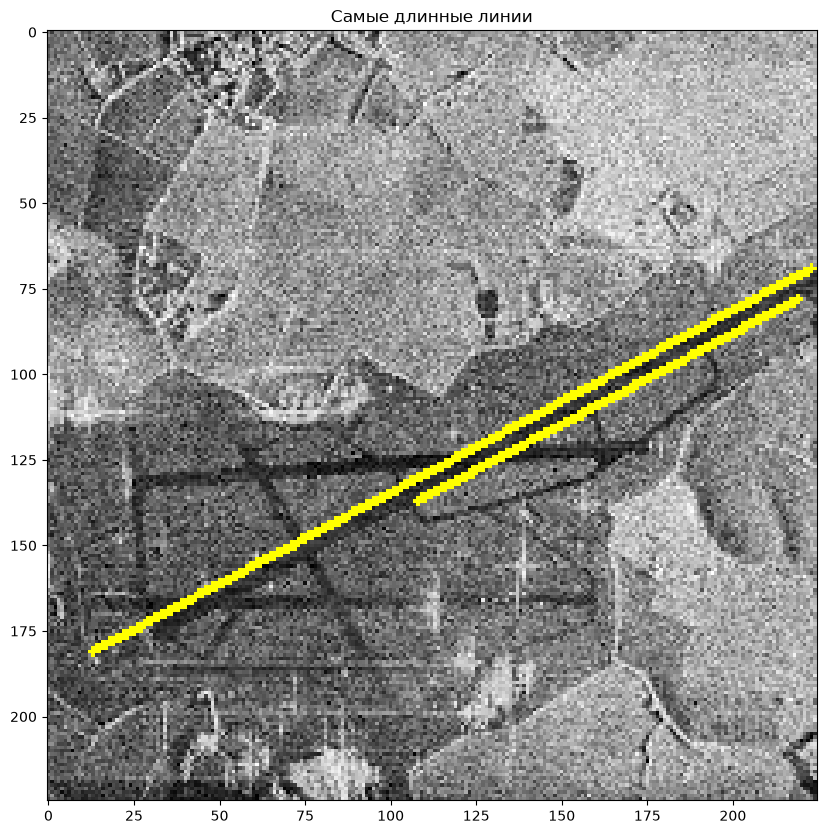

In [23]:
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(image_with_lines, cv2.COLOR_BGR2RGB))
plt.title('Самые длинные линии')
plt.show()

In [54]:
#Вывелись лишнии линии, но самый длинный настоящий участок оказался вдоль дороги

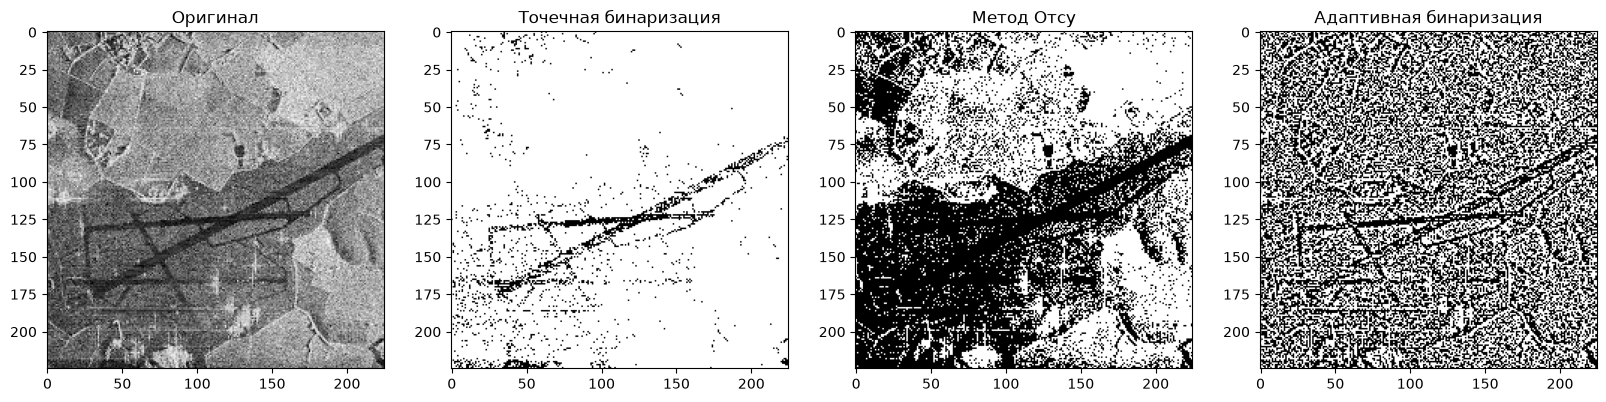

In [55]:
import copy
bin_img = copy.deepcopy(image_gray)
T_point = 50
bin_img[image_gray < T_point] = 0
bin_img[image_gray >= T_point] = 255
_, otsu = cv2.threshold(image_gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
adaptive = cv2.adaptiveThreshold(image_gray, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 11, 2)

plt.figure(figsize=(20, 5))
plt.subplot(1, 4, 1), plt.imshow(image_gray, cmap='gray'), plt.title('Оригинал')
plt.subplot(1, 4, 2), plt.imshow(bin_img, cmap='gray'), plt.title('Точечная бинаризация')
plt.subplot(1, 4, 3), plt.imshow(otsu, cmap='gray'), plt.title('Метод Отсу')
plt.subplot(1, 4, 4), plt.imshow(adaptive, cmap='gray'), plt.title('Адаптивная бинаризация')
plt.show()

In [57]:
#Лучше всего дорожный участок выделился при адаптивной бинаризации